# Cuvis Python SDK Example 6
## Reference spectra: White target reflectance and white spectrum

Cuvis 3.6 adds two new reference types to the *ProcessingContext*. Both are **spectra** (one value per wavelength) instead of full reference measurements:

 - `ReferenceType.TargetSpectrum`: The reflectance of the white target you recorded your White reference from. Without it, the SDK assumes the white target reflects 100% at every wavelength (by default, see *Constant reflectivity* below). Real targets don't (e.g. a 95% white panel, a 50% grey panel, or an aged, yellowed panel), and this spectrum corrects for that.
 - `ReferenceType.WhiteSpectrum`: An averaged white spectrum in dark-corrected sensor counts (e.g. averaged from a *Dark Subtract* cube) that **replaces** the White reference measurement. Use it when you don't have a full White reference recording, e.g. when you only know the spectrum of a white tile in your scene or have a stored white spectrum from an earlier recording. **Limitation:** A white spectrum corrects spectrally only. It does not correct spatial effects such as lens vignetting (see below).

**Used principles:**
 - *SessionFile* to load a recorded measurement and its references
 - *ProcessingContext* to compute reflectance cubes
 - `set_reference`, `get_reference_spectrum`, `has_reference` and `clear_reference` for the new spectrum references
 - *ImageData* as the container for spectra

**Step-by-Step outline:**
 1. Import and initialize Cuvis SDK
 2. Load the recorded measurement file using *SessionFile*
 3. Compute a baseline reflectance cube using the Dark and White reference measurements
 4. Correct the reflectance for the white target's real reflectance using a *TargetSpectrum*
 5. Replace the White reference measurement with a *WhiteSpectrum*
 6. Combine both spectra

**Prerequisites to running this example:**
 - Have a recorded measurement in *SessionFile* format (.cu3s) that contains Dark and White references *or* downloaded the provided [demo data](https://cloud.cubert-gmbh.de/s/SDKSampleData)
 - Have the Cuvis SDK **3.6 or newer** installed
 - Have Python and the requirements.txt installed

In [1]:
# If the import of cuvis fails, the most common cause is a mismatch between
# the _cuvis_ python package and the installed version of the Cuvis SDK.
# Try re-installing both and make sure that the version numbers match exactly
import cuvis
import re
import numpy as np
from matplotlib import pyplot as plt
print("Cuvis Python SDK Example 6")

# Initialize the Cuvis SDK using a settings-directory
# This is optional (all settings have defaults),
# but enables you to optimize Cuvis' performance on your system using the settings
# Your camera and the default Cuvis installation both provide these settings files
print("Initializing Cuvis")
cuvis.General.init("./settings")
print(cuvis.version())

Cuvis Python SDK Example 6
Initializing Cuvis
CUBERT SDK v. 3.6.0 build: 8bd07b4b38d81bfec12a359686323aa129a2037a


In [2]:
# Enter a path applicable to your setup here
import os
session_file_path = "./SDK_Training_Example_Data/WinterUlm_X20P.cu3s"
assert os.path.exists(session_file_path), f"Demo session file not found: {session_file_path}"

# Load the SessionFile
print(F"Loading Session File '{session_file_path}'")
session = cuvis.SessionFile(session_file_path)

# The demo file contains Dark and White references, which the ProcessingContext loads automatically
processing_context = cuvis.ProcessingContext(session)
processing_context.processing_mode = cuvis.ProcessingMode.Reflectance
for ref_type in cuvis.ReferenceType:
    print(F"{ref_type.name:>15}: {'set' if processing_context.has_reference(ref_type) else '-'}")

Loading Session File './SDK_Training_Example_Data/WinterUlm_X20P.cu3s'


           Dark: set
          White: set
      WhiteDark: -
          SpRad: set
       Distance: set
  WhiteSpectrum: -
 TargetSpectrum: -


#### Use a fresh Measurement for every reference configuration
`apply()` modifies the *Measurement* in place.
To compare different reference configurations side by side, this example fetches a fresh *Measurement* from the *SessionFile* for each one.

A reference spectrum set on the *ProcessingContext* is used only while it is set: Once it is cleared, or a White measurement was set in place of a *WhiteSpectrum*, the next `apply()` no longer uses it, also on a *Measurement* that was already processed with it.
A spectrum stored in a measurement's file (a session file, a *.cu3sp* file or inline in a *.cu3*) is an implicit reference: The *ProcessingContext* uses it whenever it has no explicit spectrum of that type. `has_reference` reports explicit references only, and `measurement.clear_implicit_reference(cuvis.ReferenceType.TargetSpectrum)` removes the implicit one.

In [3]:
# Helper functions
def process_fresh(pc):
    # Fetch the first measurement from the session file and compute a cube with the current references
    measurement = session.get_measurement(0)
    pc.apply(measurement)
    return measurement

def reflectance(measurement):
    # Reflectance cubes are stored as unsigned 16 bit integers: 10000 = 100%.
    # Convert to a fraction (1.0 = 100%) for easier comparison
    return np.asarray(measurement.cube.array, dtype=np.float32) / 10000

#### Baseline: Reflectance from Dark and White reference measurements
This is the classic reflectance computation also shown in *Example 3*.
The White reference measurement defines 100% reflectance, ie. by default the SDK assumes that the white target reflects all light at every wavelength.

In [4]:
baseline_measurement = process_fresh(processing_context)
baseline = reflectance(baseline_measurement)
wavelengths = np.asarray(baseline_measurement.cube.wavelength, dtype=np.float32)
print(F"Cube: {baseline.shape[1]} x {baseline.shape[0]} pixel, {len(wavelengths)} channels from {wavelengths[0]:.0f}nm to {wavelengths[-1]:.0f}nm")

# Pixel used for spectrum plots throughout this example
x, y = baseline.shape[1] // 2, baseline.shape[0] // 2
# The channels below 400nm receive almost no light in this recording, so their reflectance is mostly noise.
# They are left out of the plots
shown = wavelengths >= 400

Cube: 410 x 410 pixel, 164 channels from 350nm to 1002nm


#### Target Spectrum - The white target's real reflectance
White targets are sold with a calibration certificate that lists their reflectance at a set of wavelengths.
Set this curve as the *TargetSpectrum* and the SDK scales the reflectance by it, per wavelength:

$\text{reflectance}_{\text{corrected}}(\lambda) = \text{reflectance}(\lambda) \cdot \text{target}(\lambda)$

*Please note:*
 - The values are **fractions**: 1.0 = 100% reflectance, 0.95 = 95%.
 - Wavelengths are given in nanometers.
 - The spectrum must **cover the entire wavelength range of the cube**. Otherwise, processing fails with *"Could not process measurement."*
 - The SDK interpolates linearly between the given points, so they do not need to match the cube's wavelengths.
 - A spectrum can be passed either as a tuple `(wavelengths, values)` of 1-D arrays or as an *ImageData* with wavelengths.

In [5]:
# Example certificate of a white target (illustrative values, use the certificate of your own target):
# wavelength [nm] and reflectance as fraction
certificate_wavelengths = np.array([300, 350, 400, 450, 500, 600, 700, 800, 900, 1000, 1100], dtype=np.float32)
certificate_reflectance = np.array([0.80, 0.86, 0.91, 0.94, 0.95, 0.96, 0.96, 0.96, 0.95, 0.94, 0.93], dtype=np.float32)

# Set as a tuple (wavelengths, values) ...
processing_context.set_reference((certificate_wavelengths, certificate_reflectance), cuvis.ReferenceType.TargetSpectrum)

# ... or equivalently as an ImageData:
# target = cuvis.ImageData.from_array(certificate_reflectance, wavelength=list(certificate_wavelengths))
# processing_context.set_reference(target, cuvis.ReferenceType.TargetSpectrum)

print("Target spectrum set:", processing_context.has_reference(cuvis.ReferenceType.TargetSpectrum))

# Read the spectrum back from the ProcessingContext. It is returned as an ImageData of shape (1, 1, n)
stored_target = processing_context.get_reference_spectrum(cuvis.ReferenceType.TargetSpectrum)
print(F"Stored target spectrum: {stored_target.channels} values, {stored_target.wavelength[0]:.0f}nm to {stored_target.wavelength[-1]:.0f}nm")

Target spectrum set: True
Stored target spectrum: 11 values, 300nm to 1100nm


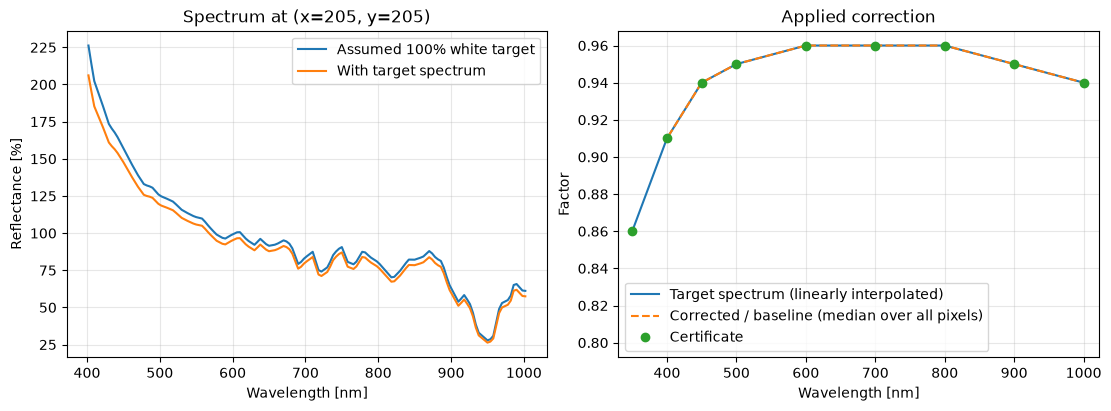

Largest deviation of the applied correction from the target spectrum: 0.0000


In [6]:
target_measurement = process_fresh(processing_context)
with_target = reflectance(target_measurement)

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)

ax0.plot(wavelengths[shown], baseline[y, x, shown] * 100, label="Assumed 100% white target")
ax0.plot(wavelengths[shown], with_target[y, x, shown] * 100, label="With target spectrum")
ax0.set_xlabel("Wavelength [nm]")
ax0.set_ylabel("Reflectance [%]")
ax0.set_title(F"Spectrum at (x={x}, y={y})")
ax0.legend()
ax0.grid(True, alpha=0.3)

# The ratio of both cubes is the target spectrum, linearly interpolated onto the cube's wavelengths
expected_correction = np.interp(wavelengths, certificate_wavelengths, certificate_reflectance)
valid = baseline > 0.05  # ignore dark pixels, where the uint16 rounding dominates the ratio
ratio = np.array([np.median(with_target[:, :, c][valid[:, :, c]] / baseline[:, :, c][valid[:, :, c]]) for c in range(len(wavelengths))])
ax1.plot(wavelengths, expected_correction, label="Target spectrum (linearly interpolated)")
ax1.plot(wavelengths[shown], ratio[shown], "--", label="Corrected / baseline (median over all pixels)")
ax1.plot(certificate_wavelengths, certificate_reflectance, "o", label="Certificate")
ax1.set_xlim(wavelengths[0] - 20, wavelengths[-1] + 20)
ax1.set_xlabel("Wavelength [nm]")
ax1.set_ylabel("Factor")
ax1.set_title("Applied correction")
ax1.legend()
ax1.grid(True, alpha=0.3)
plt.show()

deviation = np.abs(ratio[shown] - expected_correction[shown]).max()
print(F"Largest deviation of the applied correction from the target spectrum: {deviation:.4f}")

#### Constant reflectivity
If the exact curve of your target is not known, but its reflectivity is, e.g. a panel specified as "95% reflectance", use a constant target spectrum.
This is the same as the constant reflectivity option in CuvisNEXT.

Two points spanning the cube's wavelength range are enough.

Alternatively, set a constant target reflectivity for all processing in *cuvis.settings* (in the settings directory passed to `cuvis.General.init`):
`<property id="white_target_reflectivity_percentage" value="95" />` (default: 100).
An explicitly set target spectrum overrides this setting.

In [7]:
# A constant 95% reflectivity across the whole wavelength range
constant_target = (
    np.array([wavelengths[0], wavelengths[-1]], dtype=np.float32),
    np.array([0.95, 0.95], dtype=np.float32))
processing_context.set_reference(constant_target, cuvis.ReferenceType.TargetSpectrum)

with_constant_target = reflectance(process_fresh(processing_context))
print(F"Corrected / baseline (median over all pixels): {np.median(with_constant_target[valid] / baseline[valid]):.4f}")

Corrected / baseline (median over all pixels): 0.9500


In [8]:
# Remove the target spectrum again: the SDK goes back to the default white target reflectivity
# (100%, or the white_target_reflectivity_percentage setting)
processing_context.clear_reference(cuvis.ReferenceType.TargetSpectrum)
print("Target spectrum set:", processing_context.has_reference(cuvis.ReferenceType.TargetSpectrum))

Target spectrum set: False


#### White Spectrum - Replace the White reference measurement
A *WhiteSpectrum* is a single averaged spectrum of the white target in **dark-corrected sensor counts**.
It replaces the White reference measurement: The two are **mutually exclusive**, setting one clears the other.

Besides the counts, the SDK needs to know how to interpret them:
 - `effective_bit_depth` (required, 1 to 16): How many bits of each count are significant. A count of 4095 is full scale for a 12 bit sensor, but only 1/16 of full scale for a 16 bit sensor. Use the bit depth of the sensor's pixel format, e.g. 12 for *Mono12Packed*. Counts above the full scale of this bit depth are rejected.
 - `integration_time` (in ms): The integration time the counts were recorded with. By default (`correct_ref_integration_time="false"` in *cuvis.settings*), the SDK does not use this value: Record the white spectrum with the same integration time as your measurements. With `correct_ref_integration_time="true"`, the reflectance is scaled by the white spectrum's integration time / the measurement's integration time.

As for the target spectrum, the wavelengths must cover the cube's entire wavelength range.

Here, the white spectrum is taken from the White reference measurement stored in the demo file: It is processed in *Dark Subtract* mode and averaged over a region in the image center.
In your application, it could be the averaged spectrum of a white tile visible in your scene, or a spectrum stored from an earlier recording.

*Please note:* The demo white spectrum has 0 counts on its first channels (350 to 358nm), where almost no light reaches the sensor. Zero counts give no meaningful reflectance: Setting a white spectrum with zero counts logs a warning, and processing flags the whole cube as white-dark underflow in its info layer.

In [9]:
# Get the White reference measurement and compute its dark-corrected cube in a separate ProcessingContext
# (the white spectrum must be in dark-corrected counts, so use DarkSubtract mode, not Raw)
white_measurement = processing_context.get_reference(cuvis.ReferenceType.White)
dark_subtract_context = cuvis.ProcessingContext(session)
dark_subtract_context.processing_mode = cuvis.ProcessingMode.DarkSubtract
dark_subtract_context.apply(white_measurement)
white_cube = white_measurement.cube

# Average the dark-corrected counts over a 40 x 40 pixel region in the image center
roi = 20
white_counts = np.asarray(white_cube.array[y - roi:y + roi, x - roi:x + roi, :], dtype=np.float64).mean(axis=(0, 1))
white_counts = np.round(white_counts).astype(np.uint16)

# Effective bit depth from the sensor's pixel format, e.g. "Mono12Packed" -> 12
pixel_format = white_measurement.data["IMAGE_info"].pixel_format
bit_depth = int(re.search(r"\d+", pixel_format).group())

print(F"White spectrum: {len(white_counts)} values, {white_counts.min()} to {white_counts.max()} counts")
print(F"Pixel format {pixel_format} -> effective bit depth {bit_depth}")
print(F"Integration time: {white_measurement.integration_time} ms")

White spectrum: 164 values, 0 to 2085 counts
Pixel format Mono12Packed -> effective bit depth 12
Integration time: 7.0 ms


In [10]:
processing_context.set_reference(
    (white_cube.wavelength, white_counts),
    cuvis.ReferenceType.WhiteSpectrum,
    effective_bit_depth=bit_depth,
    integration_time=white_measurement.integration_time)

# Setting the white spectrum removed the White reference measurement
print("White spectrum set:   ", processing_context.has_reference(cuvis.ReferenceType.WhiteSpectrum))
print("White measurement set:", processing_context.has_reference(cuvis.ReferenceType.White))

# The white spectrum reads back with its bit depth and integration time as additional attributes
stored_white = processing_context.get_reference_spectrum(cuvis.ReferenceType.WhiteSpectrum)
print(F"Stored white spectrum: {stored_white.channels} values, "
      F"effective bit depth {stored_white.effective_bit_depth}, integration time {stored_white.integration_time} ms")

White spectrum set:    True
White measurement set: False
Stored white spectrum: 164 values, effective bit depth 12, integration time 7.0 ms


#### Limitation: A White Spectrum does not correct spatial effects
A White reference **measurement** has a white spectrum for **every pixel**.
Besides the spectral correction, it also corrects spatial effects, like the vignetting of the lens or an uneven illumination of the scene.

A *WhiteSpectrum* is a single spectrum applied to the **whole image** equally. **It does not correct spatial effects**, so lens vignetting and uneven illumination remain in the reflectance cube.
This is an intended limitation of the current implementation, the first iteration of this feature: Some cameras allow you to exchange the objective, which makes a fixed, calibrated spatial correction invalid in some cases.

If you need spatially accurate reflectance across the whole image, record a White reference measurement.

The comparison below shows the effect: In the image center, where the white spectrum was taken, both agree. Towards the edges, the reflectance computed from the white spectrum drops, following the vignetting of the lens.

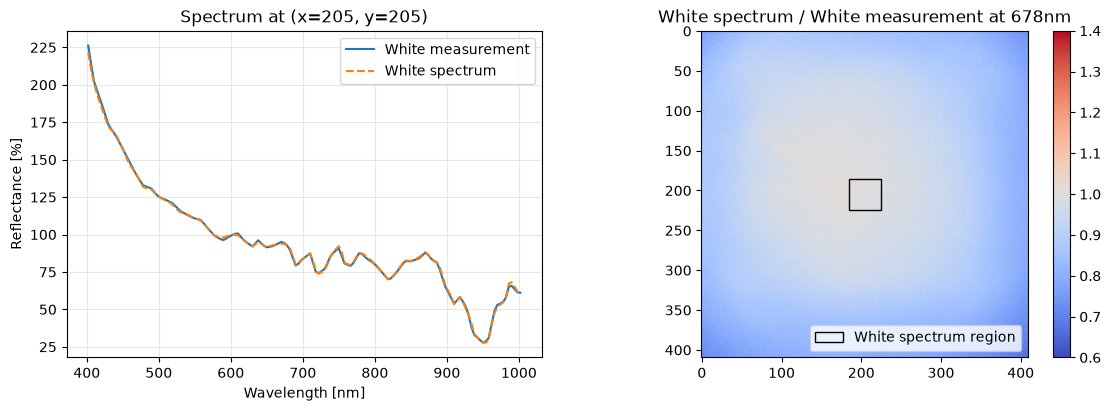

Ratio at 678nm: image center 1.001, top left corner 0.831


In [11]:
white_spectrum_measurement = process_fresh(processing_context)
with_white_spectrum = reflectance(white_spectrum_measurement)

c = len(wavelengths) // 2
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)

ax0.plot(wavelengths[shown], baseline[y, x, shown] * 100, label="White measurement")
ax0.plot(wavelengths[shown], with_white_spectrum[y, x, shown] * 100, "--", label="White spectrum")
ax0.set_xlabel("Wavelength [nm]")
ax0.set_ylabel("Reflectance [%]")
ax0.set_title(F"Spectrum at (x={x}, y={y})")
ax0.legend()
ax0.grid(True, alpha=0.3)

ratio_image = with_white_spectrum[:, :, c] / np.maximum(baseline[:, :, c], 1e-4)
im = ax1.imshow(ratio_image, cmap="coolwarm", vmin=0.6, vmax=1.4)
ax1.add_patch(plt.Rectangle((x - roi, y - roi), 2 * roi, 2 * roi, fill=False, color="k", label="White spectrum region"))
ax1.set_title(F"White spectrum / White measurement at {wavelengths[c]:.0f}nm")
ax1.legend(loc="lower right")
fig.colorbar(im, ax=ax1, fraction=0.046, pad=0.04)
plt.show()

print(F"Ratio at {wavelengths[c]:.0f}nm: image center {np.median(ratio_image[y - roi:y + roi, x - roi:x + roi]):.3f}, "
      F"top left corner {np.median(ratio_image[:2 * roi, :2 * roi]):.3f}")

#### Combining White Spectrum and Target Spectrum
Both spectra can be used together. A typical use case: A white or grey tile with known reflectance is visible in your scene.
Its averaged dark-corrected spectrum is the *WhiteSpectrum*, its certified reflectance is the *TargetSpectrum*.

The target spectrum is independent of the white source: It stays set when switching between the White measurement and the white spectrum.

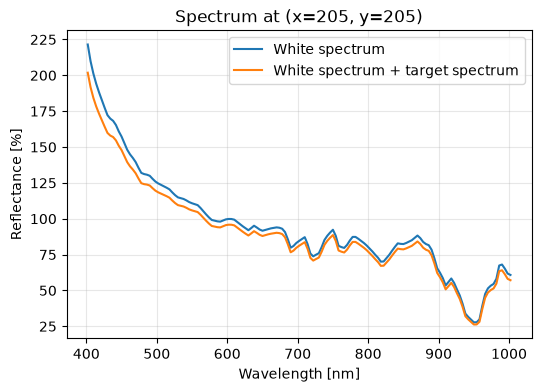

In [12]:
processing_context.set_reference((certificate_wavelengths, certificate_reflectance), cuvis.ReferenceType.TargetSpectrum)
combined = reflectance(process_fresh(processing_context))

plt.figure(figsize=(6, 4))
plt.plot(wavelengths[shown], with_white_spectrum[y, x, shown] * 100, label="White spectrum")
plt.plot(wavelengths[shown], combined[y, x, shown] * 100, label="White spectrum + target spectrum")
plt.xlabel("Wavelength [nm]")
plt.ylabel("Reflectance [%]")
plt.title(F"Spectrum at (x={x}, y={y})")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [13]:
# Restore the original state: setting the White measurement again clears the white spectrum
processing_context.set_reference(white_measurement, cuvis.ReferenceType.White)
processing_context.clear_reference(cuvis.ReferenceType.TargetSpectrum)
for ref_type in cuvis.ReferenceType:
    print(F"{ref_type.name:>15}: {'set' if processing_context.has_reference(ref_type) else '-'}")

# The result matches the baseline again
restored = reflectance(process_fresh(processing_context))
print("Identical to baseline:", np.array_equal(restored, baseline))

           Dark: set
          White: set
      WhiteDark: -
          SpRad: set
       Distance: set
  WhiteSpectrum: -
 TargetSpectrum: -


Identical to baseline: True
